<a href="https://colab.research.google.com/github/Fespinoza1477/A04-Custering/blob/main/notebook_6_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Fabrizzio Espinoza

**Date:** 10/14/2026

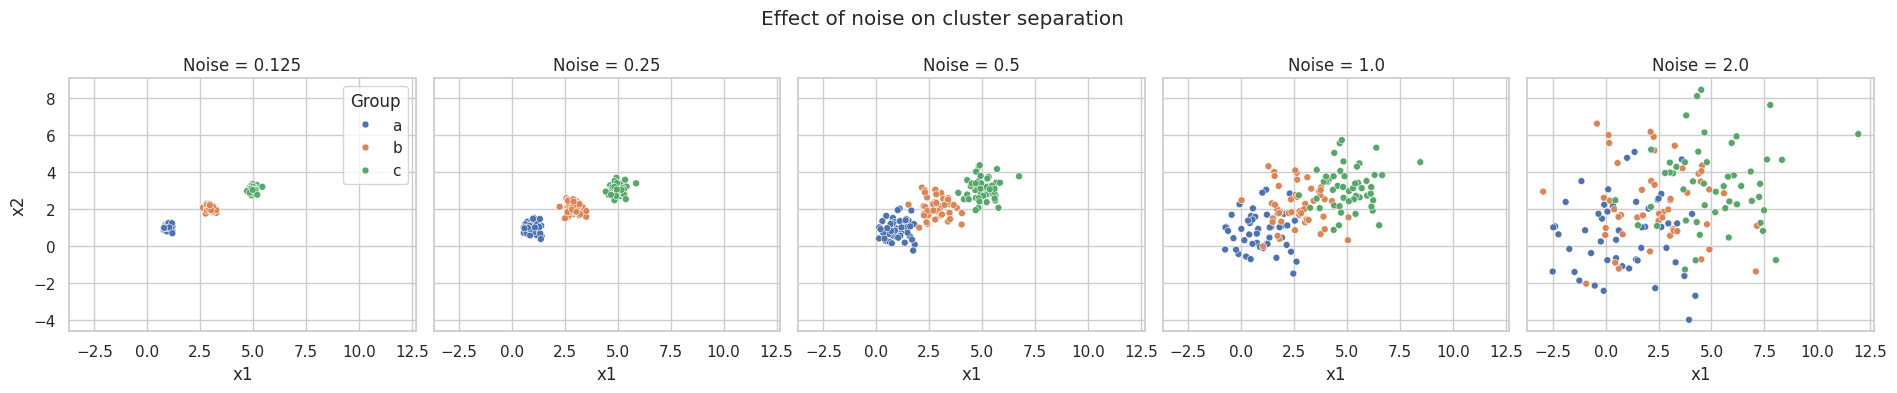

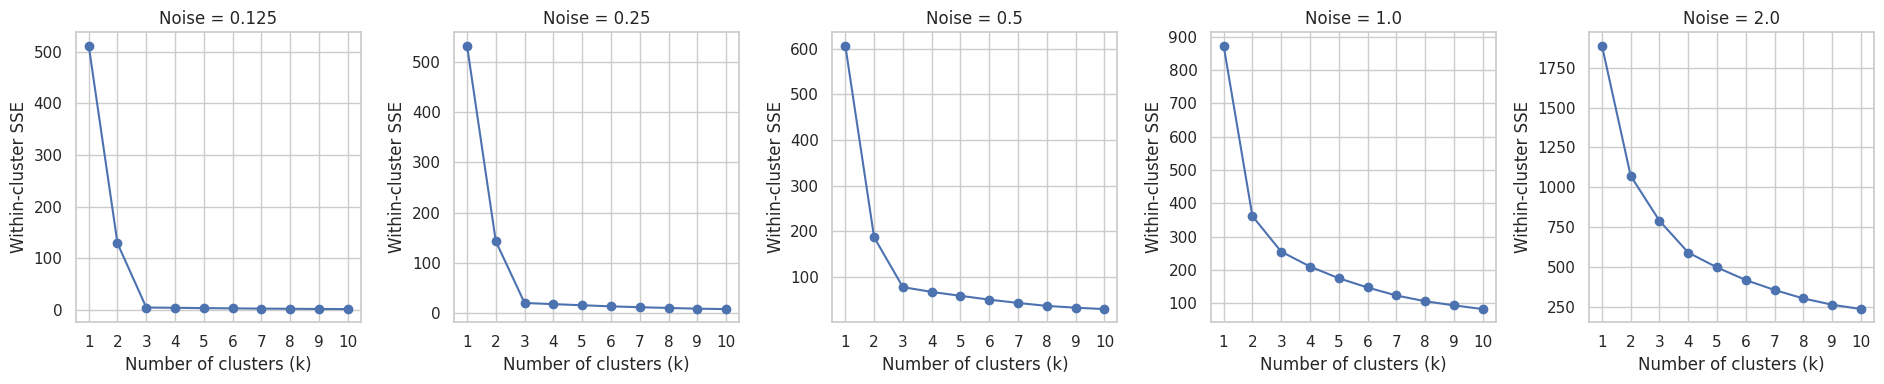

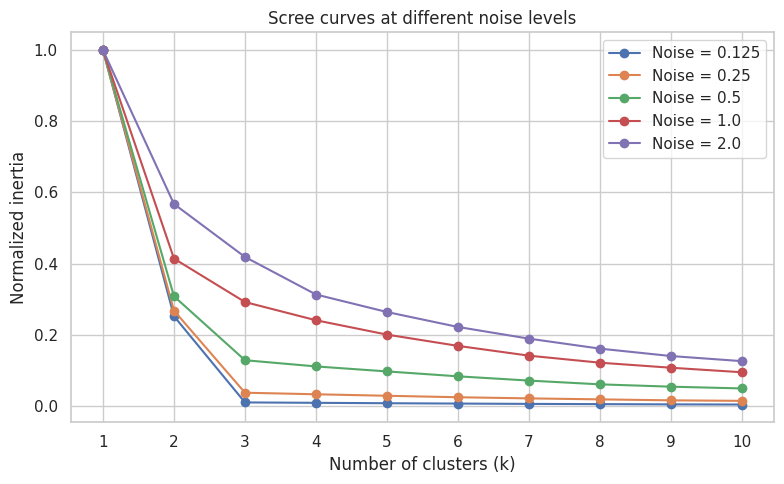

Number of countries: 148
Duplicate country names: 0
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                       

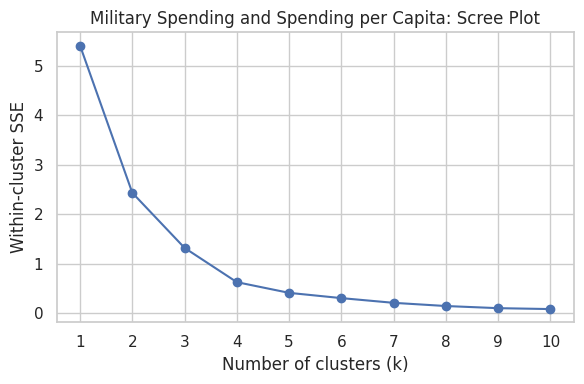

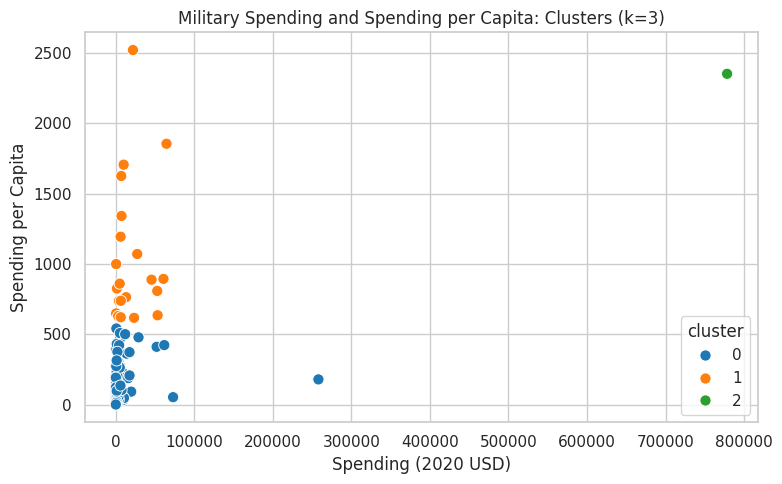


Countries per cluster:
cluster
0    126
1     21
2      1
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                                 \
                      count        mean        std         min         25%   
cluster                                                                      
0                     126.0    5943.346  24858.961       8.622     162.762   
1                      21.0   19975.991  21749.737     405.790    4980.428   
2                       1.0  778397.200        NaN  778397.200  778397.200   

                                           Spending per Capita            \
                50%         75%        max               count      mean   
cluster                                                                    
0           580.758    3225.333  257973.43               126.0   122.035   
1          7269.880   27300.895   64558.40                21.0  1046.434   
2        778397.200  778397.200  778397.20                 1.0  2351.632   

                                                                    
             std       min       25%       50%       75%       max  
cluster                                                             
0        140.041     0.580    18.506    58.809   188.249   541.155  
1        501.632   616.854   737.690   859.881  1193.599  2520.399  
2            NaN  2351.632  2351.632  2351.632  2351.632  2351.632


Mean values by cluster:


,Spending (2020 USD),Spending per Capita
cluster,,
0,5943.346,122.035
1,19975.991,1046.434
2,778397.200,2351.632



United States:


,Country,Spending (2020 USD),Spending per Capita,cluster
5540,United States of America,778397.2,2351.631858,2


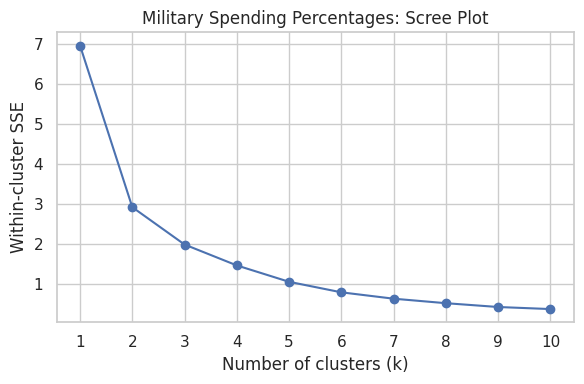

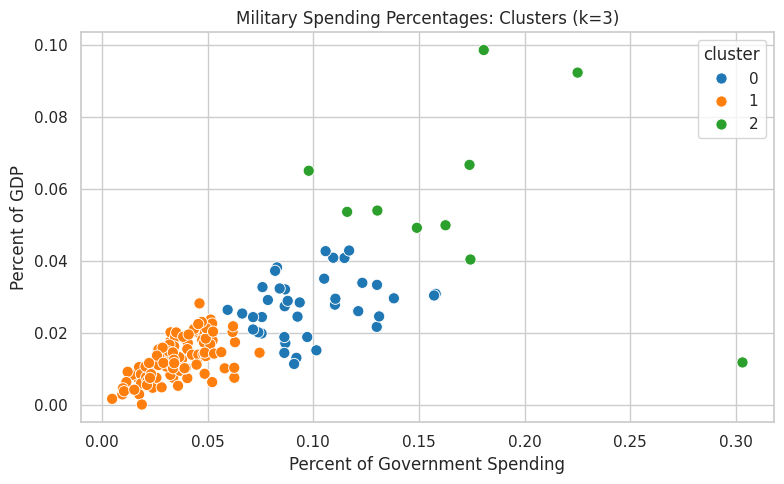


Countries per cluster:
cluster
0    39
1    99
2    10
Name: count, dtype: int64

Descriptive statistics by cluster:


Percent of Government Spending                                     \
                                 count   mean    std    min    25%    50%   
cluster                                                                     
0                                 39.0  0.099  0.024  0.060  0.082  0.092   
1                                 99.0  0.036  0.015  0.005  0.026  0.034   
2                                 10.0  0.171  0.059  0.098  0.135  0.168   

                      Percent of GDP                                     \
           75%    max          count   mean    std    min    25%    50%   
cluster                                                                   
0        0.113  0.158           39.0  0.027  0.008  0.011  0.021  0.028   
1        0.047  0.075           99.0  0.013  0.006  0.000  0.008  0.013   
2        0.179  0.303           10.0  0.058  0.025  0.012  0.049  0.054   

                       
           75%    max  
cluster                
0        0.032  0.043  
1        0.017  0.028  
2        0.066  0.098


Mean values by cluster:


,Percent of Government Spending,Percent of GDP
cluster,,
0,0.099,0.027
1,0.036,0.013
2,0.171,0.058



United States:


,Country,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,0.081976,0.037179,0


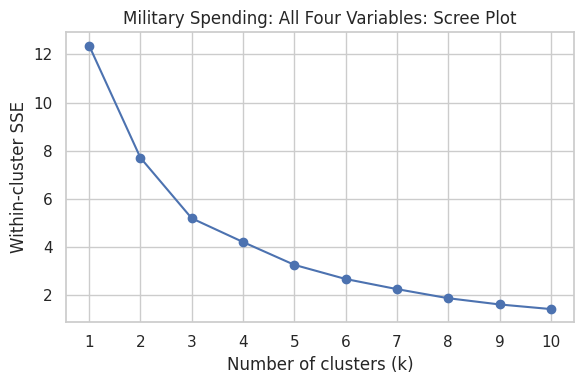

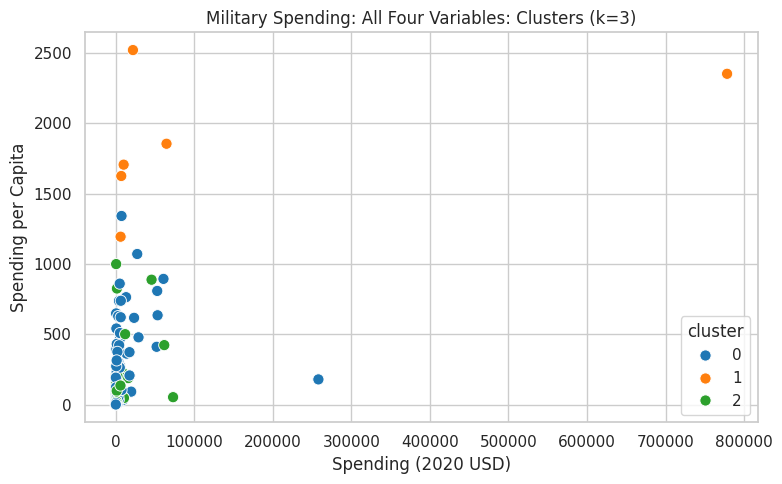


Countries per cluster:
cluster
0    111
1      6
2     31
Name: count, dtype: int64

Descriptive statistics by cluster:


Spending (2020 USD)                                              \
                      count        mean         std       min       25%   
cluster                                                                   
0                     111.0    7086.473   26479.380     8.622   130.010   
1                       6.0  147964.582  309635.190  6095.709  7700.425   
2                      31.0    8786.087   17901.909   162.373   467.788   

                                          Spending per Capita            ...  \
               50%        75%         max               count      mean  ...   
cluster                                                                  ...   
0          567.651   3910.107  257973.430               111.0   196.927  ...   
1        15897.571  53872.942  778397.200                 6.0  1875.151  ...   
2         1404.787   7739.166   72937.064                31.0   212.689  ...   

        Percent of Government Spending        Percent of GDP                \
                                   75%    max          count   mean    std   
cluster                                                                      
0                                0.051  0.092          111.0  0.013  0.006   
1                                0.165  0.225            6.0  0.063  0.028   
2                                0.135  0.303           31.0  0.033  0.011   

                                            
           min    25%    50%    75%    max  
cluster                                     
0        0.000  0.009  0.014  0.018  0.028  
1        0.029  0.041  0.059  0.085  0.098  
2        0.012  0.028  0.032  0.041  0.067  

[3 rows x 32 columns]


Mean values by cluster:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033



United States:


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


In [1]:
# Your Phase 1 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0, :], "x2": X1[1, :], "group": "a"
    })
    gdf2 = pd.DataFrame({
        "x1": X2[0, :], "x2": X2[1, :], "group": "b"
    })
    gdf3 = pd.DataFrame({
        "x1": X3[0, :], "x2": X3[1, :], "group": "c"
    })

    return pd.concat([gdf1, gdf2, gdf3], ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
#1.2
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

fig, axes = plt.subplots(
    1, 5, figsize=(19, 4), sharex=True, sharey=True
)

for i, (noise, data) in enumerate(datasets.items()):
    sns.scatterplot(
        data=data,
        x="x1",
        y="x2",
        hue="group",
        ax=axes[i],
        s=25
    )
    axes[i].set_title(f"Noise = {noise}")

    if i > 0:
        axes[i].get_legend().remove()

axes[0].legend(title="Group")
fig.suptitle("Effect of noise on cluster separation")
plt.tight_layout()
plt.show()
#As the noise increases, the three clusters become less visually distinct. At a standard deviation of 0.125, the groups are compact and clearly separated. At 0.25, they remain relatively distinct, while at 0.5, the points spread out and begin to overlap. At 1.0, there is considerably more overlap, making it harder to distinguish the groups. At 2.0, the points overlap heavily, so the original three groups are much less apparent. This demonstrates that increasing noise makes it more difficult for a clustering algorithm to identify the underlying group structure.
#1.3
K_RANGE = range(1, 11)
inertias_by_noise = {}

for noise, data in datasets.items():
    X = data[["x1", "x2"]].to_numpy()
    inertias = []

    for k in K_RANGE:
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=100
        )
        model.fit(X)
        inertias.append(model.inertia_)

    inertias_by_noise[noise] = inertias
fig, axes = plt.subplots(1, 5, figsize=(19, 4))

for ax, (noise, inertias) in zip(
    axes, inertias_by_noise.items()
):
    ax.plot(list(K_RANGE), inertias, marker="o")
    ax.set_title(f"Noise = {noise}")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Within-cluster SSE")
    ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))

for noise, inertias in inertias_by_noise.items():
    normalized = np.array(inertias) / inertias[0]
    plt.plot(
        list(K_RANGE),
        normalized,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.xlabel("Number of clusters (k)")
plt.ylabel("Normalized inertia")
plt.title("Scree curves at different noise levels")
plt.xticks(list(K_RANGE))
plt.legend()
plt.tight_layout()
plt.show()
#Iniertia decreases as k increases bcause adding more centroids allows the algorithm to fit the observations more closely. At low noise levels, the scree plot generally has a clearer bend around k = 3, which is consistent with the three groups used to generate the data. As noise increases, the points spread farther from their original centers and overlap more, making the elbow less distinct. Consequently, selecting the optimal k becomes more subjective. The normalized plot helps compare the shapes of the curves even though their absolute inertia values differ.
#1.4
#The elbow method involves plotting inertia against the number of clusters and identifying the point where increasing k produces diminishing improvements. For ex, moving from 1 to 3 clusters can substantially reduce within-cluster variation when the data contains three distinct groups. Adding many more clusters may reduce the variation further, but each additional cluster provides a smaller improvement and makes the model more complex. In this simulation, k = 3 is a natural reference because the data was generated from three centers. However, as noise increases, the group overlap and the elbow becomes less obvious. The elbow method is therefor a useful heuristic rather than a guarantee of the uniquely correct number of clusters.
#2.1
import pandas as pd
import numpy as np

DATA_PATH = "/content/SIPRI Military Expenditure Database.csv"

sipri = pd.read_csv(DATA_PATH)

df2020 = sipri[sipri["Year"] == 2020].dropna().copy()

variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

print("Number of countries:", len(df2020))
print("Duplicate country names:",
      df2020["Country"].duplicated().sum())

print(df2020[variables].dtypes)
print(df2020[variables].describe())
#Filtering the spllied dataset to 2020 and removing rows with missing values leaves 148 as expected. The 4 variables used for clustering are already numeric, and there are no duplicate country names among the remaining records. The index column is only an identifier and should not be used as a clustering variable. The year column should also be excluded because every observation is from 2020. No additional mandatory cleaning is apparent from these checks. However, the percentage variables should be interpreted carefully. In this dataset, values are stored as fractions.
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

def cluster_analysis(data, selected_vars, k=3, title="K-means"):

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[selected_vars])


    inertias = []

    for candidate_k in range(1, 11):
        model = KMeans(
            n_clusters=candidate_k,
            n_init=50,
            random_state=100
        )
        model.fit(X_scaled)
        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(range(1, 11), inertias, marker="o")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster SSE")
    plt.title(f"{title}: Scree Plot")
    plt.xticks(range(1, 11))
    plt.tight_layout()
    plt.show()


    model = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=100
    )

    result = data[["Country"] + selected_vars].copy()
    result["cluster"] = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=result,
        x=selected_vars[0],
        y=selected_vars[1],
        hue="cluster",
        palette="tab10",
        s=65
    )
    plt.title(f"{title}: Clusters (k={k})")
    plt.tight_layout()
    plt.show()

    print("\nCountries per cluster:")
    print(result["cluster"].value_counts().sort_index())

    print("\nDescriptive statistics by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .describe()
        .round(3)
    )

    print("\nMean values by cluster:")
    display(
        result.groupby("cluster")[selected_vars]
        .mean()
        .round(3)
    )

    # United States
    print("\nUnited States:")
    display(
        result[
            result["Country"].str.contains(
                "United States", case=False, na=False
            )
        ]
    )

    return result, model, scaler
#2.2
vars_part2 = [
    "Spending (2020 USD)",
    "Spending per Capita"
]

clusters_part2, model_part2, scaler_part2 = cluster_analysis(
    df2020,
    vars_part2,
    k=3,
    title="Military Spending and Spending per Capita"
)
# The scree plot shows a substantial reduction in inertia as the number of clusters initially increases, followed by progressively smaller improvements. I use k = 3 as a starting choice for comparing the three analyses, although the elbow method is subjective and another value may also be denfible. With this choice, the US is the only country in cluster 2. Its total military expenditure is approximately 778,397 million 2020 USD, and its spending per capita is approx 2,351.63 USD. The other 2 clusters contain countries with generally lower expenditure. This indicated that the US is an extremem outlier in absolute military spending, while the remaining countries are grouped according to differences in total and per-capita expenditure.
#2.3
vars_part3 = [
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part3, model_part3, scaler_part3 = cluster_analysis(
    df2020,
    vars_part3,
    k=3,
    title="Military Spending Percentages"
)
#The results differ from Part 2 because these variables measure the relative importance of military expenditure rather than the absoulte amount spent. With k = 3, the clusters contain 99, 39, and 1 countries. Their median percentages of government spending and GDP are Approx 3.4%, 1.3%, 9.2%, 2.8%, 16.8%, and 5.4%. The US belongs to cluster 0 in this run, with military expenditure equal to approx 8.2 of government spending and 3.72% of GDP. These results show that countries spending large amounts in absolute terms do not necessarily devote the largest proportion of their national resources to the military. Conversely, a country with a smaller military budget may still have a relatively high military burden.
#2.4
all_variables = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

clusters_part4, model_part4, scaler_part4 = cluster_analysis(
    df2020,
    all_variables,
    k=3,
    title="Military Spending: All Four Variables"
)
#Using all 4 variables combines information about absolute military expenditure, per-capita expenditure, and the proportion of national resources devoted to the military. With k = 3, the US belongs to cluster 1, which contains six countries and has relatively high spending measures. The remaining countries are divided into groups with generally lower absolute expenditure and differing relative spenidng levels. This differs form Parts 2 and 3 because the algorithm now considers all four measures simultaneously. Min-max normalization places each feature on a comparable 0 to 1 scla,e but extreme observations and correlations between bariables can still influence the clustering. Therefore, using all 4 variables provides a broader view, but it does not automatically make the resulting clusters better.
#2.5
#Yes, k-means identified useful patterns in the 2020 military expenditure data. When total spending and spending per capita were used, the US was separated from the other countries because of its exceptionally high military expenditure. When the percentage variables were used, the clusters instead distinguished countries that devoted relatively small, moderate, or large shares of their resources to the military. using all 4 variables combined these different perspectives and produced a different grouping. However, k-means depends on the selected number of clusters, the scaling of variables, and the influence of outliers. CLuster numbers also have no inherent ranking or meaning. Therefore, the algorithm is useful for exploring similarities between countries, but the resulting clusters should not be treated as definitive categories or explanations of why countries spend what they do.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]